In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## hyperparameter-surface

**Figure 4: Validation loss over learning rate and weight decay.** Contours are interpolated from the 13 × 13 runs on log-spaced axes; the star marks the run with the lowest loss. The loss is lowest (1.91) at learning rate 3e-4 and weight decay 6e-3, and rises steeply at the largest learning rates, where training diverges (above 3.7 at 0.01 for every weight decay).

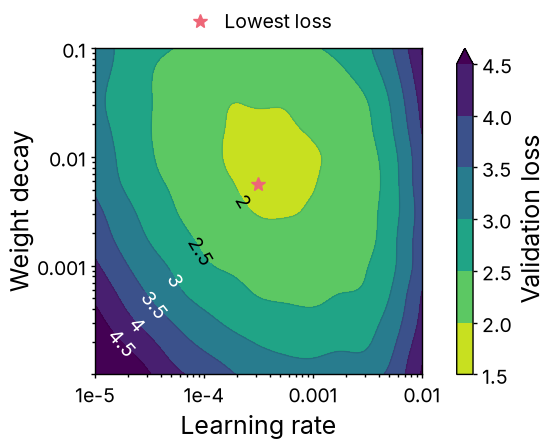

In [2]:
from matplotlib.ticker import NullFormatter
from scipy.interpolate import RectBivariateSpline

with open("../data/hyperparameter-surface.json") as f:
    data = json.load(f)
learning_rate = np.array(data["learning_rate"])
weight_decay = np.array(data["weight_decay"])
val_loss = np.array(data["val_loss"])

log_lr_fine = np.linspace(np.log10(learning_rate[0]), np.log10(learning_rate[-1]), 200)
log_wd_fine = np.linspace(np.log10(weight_decay[0]), np.log10(weight_decay[-1]), 200)
fine = RectBivariateSpline(np.log10(weight_decay), np.log10(learning_rate), val_loss)(log_wd_fine, log_lr_fine)
X, Y = np.meshgrid(10 ** log_lr_fine, 10 ** log_wd_fine)

fig, ax = plt.subplots(figsize=(2.75, 3))
ax.set_xscale("log")
ax.set_yscale("log")
cs = ax.contourf(X, Y, fine, levels=np.arange(1.5, 4.51, 0.5), cmap="viridis_r", extend="max")
lines = ax.contour(X, Y, fine, levels=cs.levels, colors=colors["ink"], alpha=0.1)
# one label per level, on the diagonal from the minimum toward the low-lr, low-wd corner, where lines are farthest apart
positions = [(2.31e-4, 3.90e-3), (9.37e-5, 1.36e-3), (5.50e-5, 7.31e-4), (3.53e-5, 4.36e-4),
             (2.47e-5, 2.87e-4), (1.77e-5, 1.95e-4)]
labels = ax.clabel(lines, fmt="%.2g", manual=positions)
for t in labels:
    t.set_alpha(1)
    t.set_color(text_color(cs.cmap(cs.norm(float(t.get_text())))))

best_i, best_j = np.unravel_index(val_loss.argmin(), val_loss.shape)
ax.plot(learning_rate[best_j], weight_decay[best_i], "*", color=colors["ours"], markerfacecolor=colors["ours"],
        markersize=2 * plt.rcParams["lines.markersize"], linestyle="none", label="Lowest loss")

ax.set_xticks([1e-5, 1e-4, 1e-3, 1e-2], labels=["1e-5", "1e-4", "0.001", "0.01"])
ax.set_yticks([1e-4, 1e-3, 1e-2, 1e-1], labels=["", "0.001", "0.01", "0.1"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_formatter(NullFormatter())
ax.grid(False)
ax.set_xlabel("Learning rate")
ax.set_ylabel("Weight decay")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0.5, ncol=1, frameon=False)
fig.colorbar(cs, ax=ax, label="Validation loss")

fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/hyperparameter-surface.pdf")
fig.savefig("../outputs/hyperparameter-surface.png")
plt.show()